# Parametric Drought-Index Insurance Simulator: Eastern Rwanda Maize
Data and modelling pipeline for the capstone proposal (Chapter Three).

### How this notebook maps to the ML track

| Requirement | Where |
|---|---|
| Data engineering | Sections 3–6c (satellite extraction, NISR yields, the 2024 reconstruction, the 2017–2021 releases) and the **Data engineering summary** at the end of Section 6 |
| Data visualization | Section 7: distributions, relationships, **correlation matrix**, **yields by district**, seasonal profiles, peak-NDVI sensitivity |
| Model architecture | Section 8: model comparison and **Model architecture** (pipeline, penalty, optimisation, tuning curve) |
| Initial performance metrics | Section 8 (RMSE, MAE, predictive R² under two validation schemes) and Section 9 (**accuracy, precision, recall, F1, confusion matrix** for the payout decision) |
| Deployment option | Section 12: FastAPI backend with Swagger UI and the Next.js dashboard |

## 1. Setup
Runs locally from the `notebook/` folder of the repository.

```bash
pip install -r notebook/requirements.txt
```

- Raw NISR survey files go in `data/nisr/` (git-ignored: NISR data is not redistributed).
- Satellite extracts are cached in `data/`; Earth Engine is only called when a cache is missing
  (and for the seasonal profiles in Section 7). The first run asks you to sign in to Earth Engine.
- Section 11 writes the model files straight into `backend/data/` for the API.

In [1]:
import os, json, csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import RidgeCV, LassoCV, LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

import ee
try:
    ee.Initialize(project='rwanda-drought-index')
except Exception:
    ee.Authenticate()   # opens a browser sign-in the first time
    ee.Initialize(project='rwanda-drought-index')

# The notebook lives in notebook/; data and the backend sit next to it.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DATA_DIR   = ROOT / 'data'
NISR_DIR   = DATA_DIR / 'nisr'
SAT_CSV    = DATA_DIR / 'satellite_district_seasons.csv'
PEAK_CSV   = DATA_DIR / 'satellite_ndvi_peak.csv'
YIELD_CSV  = DATA_DIR / 'district_maize_yield.csv'
EXPORT_DIR = ROOT / 'backend' / 'data'
print('Setup complete. Data folder:', DATA_DIR.resolve())

Setup complete. Data folder: /Users/apple/Desktop/parametric-drought-simulator/data


## 2. Configuration

In [2]:
DISTRICTS = ['Bugesera', 'Gatsibo', 'Kayonza', 'Kirehe', 'Ngoma', 'Nyagatare', 'Rwamagana']

# Season Y runs from September of Y-1 to February of Y (NISR Season A).
# Critical growth window (to confirm from the JRC crop calendar):
WIN_START_MONTH = 10   # October of Y-1
WIN_END_MONTH   = 12   # December of Y-1

YIELD_SEASONS  = list(range(2017, 2026))   # seasons with district maize yields (Sections 6-6c)
# 2017 production looks imputed by NISR (Section 6c), so it is kept in the yield table but not used
# to fit the model or choose the trigger.
TRAIN_SEASONS  = [s for s in YIELD_SEASONS if s != 2017]
CHIRPS_SEASONS = list(range(1982, 2026)) # CHIRPS starts 1981
MODIS_SEASONS  = list(range(2001, 2026)) # MODIS starts 2000

LOW_YIELD_THRESHOLD = -10.0  # % below district average, fixed before seeing results
DROUGHT_YEARS = list(range(2003, 2007)) + list(range(2013, 2018))  # Niyonsenga et al. (2024)

# Standard Season A releases (2022, 2023, 2025). 2024 is rebuilt from the raw
# Production and Screening files in Section 6b.
NISR_FILES = {2022: 'season_a_2022.sav', 2023: 'season_a_2023.csv', 2025: 'season_a_2025.csv'}
# 2017-2021 come from older Stata releases, read in Section 6c (NISR_DIR/<year>/).
NISR_2024  = {'production': '2024_extra/Rwa_raw_SeasonA2024_Production.csv',
              'screening':  '2024_extra/Rwa_raw_SeasonA2024_Screening.csv'}

## 3. Boundaries and satellite datasets
District boundaries: FAO GAUL 2025. Cropland mask: ESA WorldCover (class 40).

In [3]:
NAME_FIELD = 'GAUL2_NAME'
districts = (ee.FeatureCollection('FAO/GAUL/2025/level2')
             .filter(ee.Filter.eq('ISO3_CODE', 'RWA'))
             .filter(ee.Filter.inList(NAME_FIELD, DISTRICTS)))
found = districts.aggregate_array(NAME_FIELD).getInfo()
assert len(found) == 7, f'Only found: {found}'
print('All seven districts found')

cropland = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map').eq(40)
chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/PENTAD').select('precipitation')
modis  = ee.ImageCollection('MODIS/061/MOD13Q1')

def window(y):
    y = ee.Number(y)
    start = ee.Date.fromYMD(y.subtract(1), WIN_START_MONTH, 1)
    end   = ee.Date.fromYMD(y.subtract(1), WIN_END_MONTH, 1).advance(1, 'month')
    return start, end

def chirps_season(y):
    start, end = window(y)
    img = chirps.filterDate(start, end).sum().rename('value')   # total rainfall in the window
    return img.updateMask(cropland).set('season', y)

def modis_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)   # keep good and marginal pixels
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).mean().rename('value')
    return img.updateMask(cropland).set('season', y)

def extract(season_fn, seasons, scale, name):
    col = ee.ImageCollection(ee.List(seasons).map(season_fn))
    def reduce(img):
        fc = img.reduceRegions(collection=districts, reducer=ee.Reducer.mean(), scale=scale)
        return fc.map(lambda f: f.set('season', img.get('season')))
    feats = col.map(reduce).flatten().getInfo()['features']
    return pd.DataFrame([{'district': f['properties'][NAME_FIELD],
                          'season': int(f['properties']['season']),
                          name: f['properties'].get('mean')} for f in feats])

All seven districts found


### District shapes for the dashboard map
The same GAUL 2025 boundaries, simplified to about 200 m so the file stays small, saved for the API's
`/api/geo/districts` endpoint.

In [4]:
geo = (districts
       .map(lambda f: f.simplify(200))
       .select([NAME_FIELD], ['district'])
       .getInfo())

# Some GAUL boundaries carry stray line segments next to the polygon; keep only the area.
def polygons_only(g):
    if g['type'] != 'GeometryCollection':
        return g
    polys = []
    for part in g['geometries']:
        if part['type'] == 'Polygon':
            polys.append(part['coordinates'])
        elif part['type'] == 'MultiPolygon':
            polys.extend(part['coordinates'])
    return {'type': 'Polygon', 'coordinates': polys[0]} if len(polys) == 1 else {'type': 'MultiPolygon', 'coordinates': polys}

for f in geo['features']:
    f['geometry'] = polygons_only(f['geometry'])
assert all(f['geometry']['type'] in ('Polygon', 'MultiPolygon') for f in geo['features'])

for path in (DATA_DIR / 'eastern_districts.geojson', EXPORT_DIR / 'eastern_districts.geojson'):
    with open(path, 'w') as f:
        json.dump(geo, f)
names = sorted(f['properties']['district'] for f in geo['features'])
print(len(geo['features']), 'districts exported:', ', '.join(names))
print(f"File size: {(DATA_DIR / 'eastern_districts.geojson').stat().st_size / 1024:.0f} KB")

7 districts exported: Bugesera, Gatsibo, Kayonza, Kirehe, Ngoma, Nyagatare, Rwamagana
File size: 58 KB


## 4. Satellite extraction and anomalies
Extracted once from Earth Engine, then loaded from the cache in `data/`.

In [5]:
if os.path.exists(SAT_CSV):
    sat = pd.read_csv(SAT_CSV)
    print('Loaded cached satellite data:', sat.shape)
else:
    rain = extract(chirps_season, CHIRPS_SEASONS, 1000, 'rain_mm')
    ndvi = extract(modis_season, MODIS_SEASONS, 250, 'ndvi')
    sat = rain.merge(ndvi, on=['district', 'season'], how='left')
    sat.to_csv(SAT_CSV, index=False)
    print('Extracted and saved:', sat.shape)

def zscore(s):
    return (s - s.mean()) / s.std(ddof=1)

sat['rain_z'] = sat.groupby('district')['rain_mm'].transform(zscore)
sat['ndvi_z'] = sat.groupby('district')['ndvi'].transform(zscore)

print('\nWeather in the yield seasons (province averages):')
print(sat[sat['season'].isin(TRAIN_SEASONS)].groupby('season')[['rain_mm', 'rain_z', 'ndvi', 'ndvi_z']].mean().round(2))

Loaded cached satellite data: (308, 4)

Weather in the yield seasons (province averages):
        rain_mm  rain_z  ndvi  ndvi_z
season                               
2018     317.23   -0.20  0.61   -0.67
2019     348.49    0.31  0.62   -0.30
2020     336.88    0.14  0.66    0.72
2021     461.60    2.08  0.65    0.36
2022     325.65   -0.06  0.61   -0.59
2023     300.39   -0.43  0.63   -0.30
2024     327.77    0.00  0.68    1.25
2025     413.91    1.34  0.62   -0.74


## 5. NISR survey data
Seasonal Agricultural Survey microdata, Season A.
File formats differ by year: 2022 is SPSS, 2023 is comma-separated, 2025 is tab-separated.
The standard 2024 release omits the maize area and yield variables, so 2024 is rebuilt in Section 6b
from the raw Production and Screening files.
Seasons 2017–2021 come from older Stata releases with different file layouts (Section 6c).

In [6]:
def load_nisr(path):
    if path.endswith('.sav'):
        return pd.read_spss(path)
    with open(path, encoding='latin-1') as f:
        sep = csv.Sniffer().sniff(''.join(f.readline() for _ in range(5))).delimiter
    return pd.read_csv(path, sep=sep, low_memory=False, encoding='latin-1')

raw = {yr: load_nisr(str(NISR_DIR / NISR_FILES[yr])) for yr in NISR_FILES}
for yr, d in raw.items():
    print(f'{yr}: {d.shape[0]:,} rows, {d.shape[1]} columns')

2022: 41,589 rows, 101 columns
2023: 39,038 rows, 103 columns
2025: 34,369 rows, 101 columns


## 6. District maize yields
Plots: Eastern Province, maize (CropCategory = 'Maize', which excludes fodder maize), smallholders only.
Area (ha): Harv_area in 2022 and 2023; Crop_Area_ha in 2025 (NISR's own variables).
Production (kg): s2q21 in all years.

In [7]:
AREA_COL       = {2022: 'Harv_area', 2023: 'Harv_area', 2025: 'Crop_Area_ha'}
NISR_YIELD_COL = {2022: 'yield',     2023: 'yield',     2025: 'Yield'}

def num(s):
    return pd.to_numeric(s, errors='coerce')

def maize_plots(d, yr):
    small = d['s1q7'].astype(str).str.lower().str.startswith('small')
    m = d[(d['s1q1'] == 'East') & (d['CropCategory'] == 'Maize') & small].copy()
    m['district'] = m['s1q2'].astype(str)
    m['area_ha'] = num(m[AREA_COL[yr]])
    m['production_kg'] = num(m['s2q21'])
    return m.dropna(subset=['area_ha', 'production_kg', 'plot_weight'])

plots = {yr: maize_plots(raw[yr], yr) for yr in NISR_FILES}

for yr, m in plots.items():
    gap = (m['production_kg'] - num(m[NISR_YIELD_COL[yr]]) * m['area_ha']).abs()
    print(f'{yr}: {len(m):,} smallholder maize plots | production matches NISR yield for {(gap < 1).mean():.1%}')

print('\nPlots per district:')
print(pd.DataFrame({yr: m['district'].value_counts() for yr, m in plots.items()}).loc[DISTRICTS])

2022: 2,857 smallholder maize plots | production matches NISR yield for 100.0%
2023: 2,941 smallholder maize plots | production matches NISR yield for 100.0%
2025: 2,733 smallholder maize plots | production matches NISR yield for 100.0%

Plots per district:
           2022  2023  2025
district                   
Bugesera    365   322   328
Gatsibo     445   410   435
Kayonza     298   375   302
Kirehe      539   559   505
Ngoma       396   430   402
Nyagatare   363   427   421
Rwamagana   451   418   340


### Calculating weighted district yields

In [8]:
def district_yields(plot_table, season, area_col, production_col):
    out = []
    for dist, g in plot_table.groupby('district'):
        w = g['plot_weight']
        out.append({'district': dist, 'season': season, 'plots': len(g),
                    'yield_kg_ha': (w * g[production_col]).sum() / (w * g[area_col]).sum()})
    return out

rows = []
for yr, m in plots.items():
    rows += district_yields(m, yr, 'area_ha', 'production_kg')
yld = pd.DataFrame(rows)
yld = yld[yld['district'].isin(DISTRICTS)].reset_index(drop=True)
print(f'{len(yld)} district-seasons from the standard releases (2022, 2023, 2025)')

21 district-seasons from the standard releases (2022, 2023, 2025)


## 6b. Season A 2024: rebuilding maize area
The 2024 release has production per plot (Production file) but not the maize area. The Screening file
has the area of each crop on each plot (`crop_area`). The two are joined plot by plot:

- key: segment (`Segment_ID`), plot number (`s2q1`) and plot area rounded to 1 m² (`s2q2` / `s2q5`),
  because a plot number alone is not unique within a segment;
- exact duplicate Screening rows are dropped, and the few that stay ambiguous are excluded;
- then the same rules as the other years: Eastern Province, maize, smallholders, survey-weighted yield.

In [9]:
prod24 = load_nisr(str(NISR_DIR / NISR_2024['production']))
scr24  = load_nisr(str(NISR_DIR / NISR_2024['screening']))

def east_maize(d):
    return d[d['s1q1'].astype(str).str.contains('East', case=False)
             & (d['CropCategory'].astype(str).str.strip() == 'Maize')].copy()

p24, s24 = east_maize(prod24), east_maize(scr24)
print(f'Raw files: Production {len(prod24):,} rows, Screening {len(scr24):,} rows')
print(f'Eastern maize rows: Production {len(p24):,}, Screening {len(s24):,}')

KEY = ['Segment_ID', 's2q1', 'area_key']
for d, area in ((p24, 's2q2'), (s24, 's2q5')):
    for k in ['Segment_ID', 's2q1']:
        d[k] = pd.to_numeric(d[k], errors='coerce').astype('Int64')
    d['area_key'] = pd.to_numeric(d[area], errors='coerce').round(0)

s24 = s24.drop_duplicates(KEY + ['s3q2_1', 'crop_area'])
ambiguous = s24.duplicated(KEY, keep=False)
print(f'Screening rows still ambiguous after matching on area: {ambiguous.sum()} (excluded)')
s24 = s24[~ambiguous]

joined = p24.merge(s24[KEY + ['s3q2_1', 'crop_area']], on=KEY, how='left')
assert len(joined) == len(p24), 'The join must not duplicate Production rows'
print(f'Production maize rows: {len(p24):,} before the join | {len(joined):,} after (no plot counted twice)')
print(f"Production maize rows matched to a crop area: {joined['crop_area'].notna().mean():.1%}")

Raw files: Production 39,330 rows, Screening 54,382 rows
Eastern maize rows: Production 3,413, Screening 3,864
Screening rows still ambiguous after matching on area: 132 (excluded)
Production maize rows: 3,413 before the join | 3,413 after (no plot counted twice)
Production maize rows matched to a crop area: 98.5%


In [10]:
small = joined['s1q7'].astype(str).str.lower().str.startswith('small')
m24 = joined[small].copy()
m24['district'] = m24['s1q2'].astype(str)
for c in ['crop_area', 's2q21', 'plot_weight']:
    m24[c] = pd.to_numeric(m24[c], errors='coerce')
m24 = m24.dropna(subset=['crop_area', 's2q21', 'plot_weight'])
m24 = m24[m24['crop_area'] > 0]
plots[2024] = m24.rename(columns={'crop_area': 'area_ha', 's2q21': 'production_kg'})
print(f'2024 smallholder maize plots used: {len(m24):,}')

yld24 = pd.DataFrame(district_yields(m24, 2024, 'crop_area', 's2q21'))
yld = (pd.concat([yld, yld24[yld24['district'].isin(DISTRICTS)]], ignore_index=True)
       .sort_values(['season', 'district']).reset_index(drop=True))
assert len(yld) == len(DISTRICTS) * 4, f'Expected 28 district-seasons for 2022-2025, got {len(yld)}'

print(f'\n{len(yld)} district-seasons from 2022-2025\n')
print('District maize yield (kg/ha):')
print(yld.pivot(index='district', columns='season', values='yield_kg_ha').round(0))

2024 smallholder maize plots used: 3,147

28 district-seasons from 2022-2025

District maize yield (kg/ha):
season       2022    2023    2024    2025
district                                 
Bugesera   1420.0   780.0  1561.0  1729.0
Gatsibo    1543.0  1616.0  2165.0  2050.0
Kayonza    1079.0  1277.0  1692.0  1673.0
Kirehe     1071.0  1755.0  2529.0  2597.0
Ngoma      1727.0  1634.0  2131.0  2297.0
Nyagatare  2028.0  2944.0  3773.0  3157.0
Rwamagana  1367.0  1092.0  1737.0  1739.0


## 6c. Seasons A 2017–2021: older survey releases
NISR's microdata for earlier years come as Stata files with different layouts. Each year is read with the
same rules as 2022–2025 (Eastern Province, maize grain, smallholders, survey-weighted yield); only the files
and variable names change.

| Season | Files | Maize area | Production (kg) | Weight | Note |
|---|---|---|---|---|---|
| 2017 | SSF Crop production + Screening | `s2q7` (m²) | `s2q22` | `WH_Plot`, joined by segment and plot | production looks imputed (below); **not used for training** |
| 2018 | SSF Crop production + Screening | `Harvested_area` (m²) | `s2q21` | `WH_Plot`, joined by segment and plot | |
| 2019 | Crop production + Screening | `Harvested_Area` (ha) | `s2q21` | `Weight`, joined by segment and plot | lowest yields in the record |
| 2020 | Crop production | `Crop_Area` (ha) | `s2q21` | `Plot_weight` | |
| 2021 | Crop production + Screening_crops | `Crop_Area` from Screening_crops | `s2q21` | `finalplot_weight` | the production file's `Crop_Area` is the whole plot, not the maize share |

Every join matches all of a year's plots; 19 plots in 2021 lack a production or weight value and are dropped.

**Season A 2017** is a documented drought season, and 2,315 of its 2,955 maize plots report drought or
insufficient rain as the reason for their harvest. Yet about 46% of plots share one identical yield per district
(to the kg), no plot is below about 750 kg/ha and none is zero. NISR appears to have filled in production for
these plots, so 2017 yields say little about the drought. The season stays in the yield table, flagged, and a
sensitivity check in Section 8 shows the model trained with it.

**Seasons 2013–2016 cannot be used.** Those releases have maize area and survey weights but no harvest
quantity: their only production tables give the share of each crop sold, eaten, stored and so on (every row
sums to 100%), and their yield tables are national (2014–2016) or provincial (2013) totals. Without production
per plot there is no district yield.


In [11]:
def read_dta(path):
    """Read a Stata file, mapping value labels by hand: some NISR files repeat a label,
    which pandas' own categorical conversion refuses."""
    with pd.io.stata.StataReader(path) as r:
        d = r.read(convert_categoricals=False)
        labels = r.value_labels()
        for col, lab in zip(r._varlist, r._lbllist):
            if lab in labels and col in d:
                d[col] = d[col].map(labels[lab]).fillna(d[col])
    return d

OLD = NISR_DIR  # raw files for 2017-2021 sit in NISR_DIR/<year>/

def plots_2017_2018(yr, area, prod):
    """Small-scale farmer (SSF) files. Areas are in m2; the plot weight is in Screening."""
    cp = read_dta(OLD / str(yr) / f'SeasonA_{yr}_SSF_Crop production.dta')
    sc = read_dta(OLD / str(yr) / f'SeasonA_{yr}_SSF_Screening.dta')
    w = sc.groupby(['s1q0', 's2q2'], as_index=False)['WH_Plot'].first()   # one weight per plot
    m = cp[(cp['s1q1'] == 'East') & (cp['s2q6'] == 'Maize')]
    j = m.merge(w, left_on=['s1q0', 's2q1'], right_on=['s1q0', 's2q2'], how='left', validate='m:1')
    return pd.DataFrame({'district': j['s1q2'], 'area_ha': num(j[area]) / 1e4,
                         'production_kg': num(j[prod]), 'plot_weight': num(j['WH_Plot'])})

def plots_2019():
    """Farmer type is on the row; the weight is joined from Screening by segment and plot."""
    cp = read_dta(OLD / '2019' / 'rwa-sas-seasonA_Crop production.dta')
    sc = read_dta(OLD / '2019' / 'rwa-sas-seasonA-Screening.dta')
    w = sc.loc[sc['s2q11'] == 'Maize', ['Segment_ID', 's2q2', 'Weight']].rename(columns={'s2q2': 's2q1'})
    m = cp[(cp['s1q1'] == 'East') & (cp['s2q6'] == 'Maize') & (cp['s2q3_1'] == 'small scale farmer')]
    j = m.merge(w, on=['Segment_ID', 's2q1'], how='left', validate='m:1')
    return pd.DataFrame({'district': j['s1q2'], 'area_ha': num(j['Harvested_Area']),
                         'production_kg': num(j['s2q21']), 'plot_weight': num(j['Weight'])})

SMALL_2020 = ['Small scale farmer as individual', 'Small Scale farmer as Coperative/Company/Association,']

def plots_2020_2021(yr):
    """Same layout as 2022. In 2021 the production file's Crop_Area is the whole plot for every crop,
    so the maize share of the plot is joined from Screening_crops instead."""
    cp = read_dta(OLD / str(yr) / 'rwa-sas-seasonA_Crop production.dta')
    m = cp[(cp['s1q1'] == 'East') & (cp['s2q4'] == 'Maize') & cp['s1q7'].isin(SMALL_2020) & (cp['s1q3'] != 'LSF')]
    if yr == 2020:
        return pd.DataFrame({'district': m['s1q2'], 'area_ha': num(m['Crop_Area']),
                             'production_kg': num(m['s2q21']), 'plot_weight': num(m['Plot_weight'])})
    sc = read_dta(OLD / '2021' / 'rwa-sas-seasonA-Screening_crops.dta')
    a = sc.loc[sc['s3q1'] == 'Maize', ['Segment_ID', 's2q1', 'Crop_Area']].rename(columns={'Crop_Area': 'maize_area'})
    j = m.merge(a, on=['Segment_ID', 's2q1'], how='left', validate='m:1')
    return pd.DataFrame({'district': j['s1q2'], 'area_ha': num(j['maize_area']),
                         'production_kg': num(j['s2q21']), 'plot_weight': num(j['finalplot_weight'])})

older = {2017: plots_2017_2018(2017, 's2q7', 's2q22'),
         2018: plots_2017_2018(2018, 'Harvested_area', 's2q21'),
         2019: plots_2019(), 2020: plots_2020_2021(2020), 2021: plots_2020_2021(2021)}

rows_old = []
for yr, m in older.items():
    m['district'] = m['district'].astype(str).str.strip()
    n = len(m)
    m = m.dropna(subset=['area_ha', 'production_kg', 'plot_weight'])
    m = m[m['area_ha'] > 0]
    plots[yr] = m
    print(f'{yr}: {n:,} Eastern smallholder maize plots, {len(m):,} with area, production and weight')
    rows_old += district_yields(m, yr, 'area_ha', 'production_kg')

yld_old = pd.DataFrame(rows_old)
yld_old = yld_old[yld_old['district'].isin(DISTRICTS)]
assert len(yld_old) == 7 * len(older), 'Every district should appear in every year'
print('\nDistrict maize yield, older releases (kg/ha):')
print(yld_old.pivot(index='district', columns='season', values='yield_kg_ha').round(0))


2017: 2,955 Eastern smallholder maize plots, 2,955 with area, production and weight
2018: 2,292 Eastern smallholder maize plots, 2,292 with area, production and weight
2019: 2,651 Eastern smallholder maize plots, 2,651 with area, production and weight
2020: 3,110 Eastern smallholder maize plots, 3,110 with area, production and weight
2021: 3,193 Eastern smallholder maize plots, 3,174 with area, production and weight

District maize yield, older releases (kg/ha):
season       2017    2018    2019    2020    2021
district                                         
Bugesera   1467.0  1168.0   962.0  1312.0  1294.0
Gatsibo    1751.0  1985.0  1254.0  1854.0  1724.0
Kayonza    1498.0   839.0   587.0  1290.0  1302.0
Kirehe     1494.0  1067.0   687.0  1633.0  1227.0
Ngoma      1625.0  1373.0   796.0  1999.0  1737.0
Nyagatare  1859.0  1566.0  1131.0  2114.0  1722.0
Rwamagana  1527.0  1547.0   726.0  1793.0  1576.0


In [12]:
yld = (pd.concat([yld_old, yld], ignore_index=True)
       .sort_values(['season', 'district']).reset_index(drop=True))
yld['used_in_training'] = yld['season'].isin(TRAIN_SEASONS)
assert len(yld) == len(DISTRICTS) * len(YIELD_SEASONS), f'Expected {7 * len(YIELD_SEASONS)} district-seasons, got {len(yld)}'
print(f'{len(yld)} district-seasons with yields ({YIELD_SEASONS[0]}-{YIELD_SEASONS[-1]}); '
      f'{yld["used_in_training"].sum()} used for training')
print(yld.pivot(index='district', columns='season', values='yield_kg_ha').round(0))


63 district-seasons with yields (2017-2025); 56 used for training
season       2017    2018    2019    2020    2021    2022    2023    2024  \
district                                                                    
Bugesera   1467.0  1168.0   962.0  1312.0  1294.0  1420.0   780.0  1561.0   
Gatsibo    1751.0  1985.0  1254.0  1854.0  1724.0  1543.0  1616.0  2165.0   
Kayonza    1498.0   839.0   587.0  1290.0  1302.0  1079.0  1277.0  1692.0   
Kirehe     1494.0  1067.0   687.0  1633.0  1227.0  1071.0  1755.0  2529.0   
Ngoma      1625.0  1373.0   796.0  1999.0  1737.0  1727.0  1634.0  2131.0   
Nyagatare  1859.0  1566.0  1131.0  2114.0  1722.0  2028.0  2944.0  3773.0   
Rwamagana  1527.0  1547.0   726.0  1793.0  1576.0  1367.0  1092.0  1737.0   

season       2025  
district           
Bugesera   1729.0  
Gatsibo    2050.0  
Kayonza    1673.0  
Kirehe     2597.0  
Ngoma      2297.0  
Nyagatare  3157.0  
Rwamagana  1739.0  


### Combining yields with the satellite anomalies
Yields rise over the period (better seed and fertiliser use), so measuring each season against a flat district
average would call the early seasons poor for reasons unrelated to drought. The expected yield is therefore the
district's own level times a common province trend, fitted on log yield over the training seasons, and the
target is the percentage deviation from it.


In [13]:
train = yld[yld['used_in_training']]
SEASON_MID = train['season'].mean()

def trend_design(t):
    return pd.get_dummies(t['district']).astype(float).assign(season=t['season'] - SEASON_MID)

trend_fit = LinearRegression().fit(trend_design(train), np.log(train['yield_kg_ha']))
slope = trend_fit.coef_[-1]
demeaned = np.log(train['yield_kg_ha']) - np.log(train['yield_kg_ha']).groupby(train['district']).transform('mean')
p_trend = stats.linregress(train['season'], demeaned).pvalue
print(f'Yield trend {TRAIN_SEASONS[0]}-{TRAIN_SEASONS[-1]}: {100 * (np.exp(slope) - 1):+.1f}% a year (p = {p_trend:.1g})')

yld['expected_kg_ha'] = np.exp(trend_fit.predict(trend_design(yld)))
yld['yield_anom'] = 100 * (yld['yield_kg_ha'] - yld['expected_kg_ha']) / yld['expected_kg_ha']
yld.round(2).to_csv(YIELD_CSV, index=False)

df_all = yld.merge(sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']],
                   on=['district', 'season'], how='left')
assert df_all[['rain_z', 'ndvi_z']].notna().all().all(), 'Missing satellite values for some district-seasons'
df = df_all[df_all['used_in_training']].reset_index(drop=True)

print(f'Modelling dataset: {len(df)} rows ({len(df_all) - len(df)} more, Season A 2017, kept for the sensitivity check)\n')
print(df[['district', 'season', 'yield_kg_ha', 'expected_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z']].round(2).to_string(index=False))


Yield trend 2018-2025: +9.3% a year (p = 8e-08)
Modelling dataset: 56 rows (7 more, Season A 2017, kept for the sensitivity check)

 district  season  yield_kg_ha  expected_kg_ha  yield_anom  rain_z  ndvi_z
 Bugesera    2018      1167.87          909.79       28.37    0.25   -0.26
  Gatsibo    2018      1985.04         1281.13       54.94   -0.34   -0.14
  Kayonza    2018       838.53          847.40       -1.05   -0.37   -0.90
   Kirehe    2018      1066.80         1051.39        1.47   -0.05   -0.88
    Ngoma    2018      1372.65         1200.51       14.34   -0.08   -0.89
Nyagatare    2018      1565.95         1574.53       -0.55   -0.57   -1.32
Rwamagana    2018      1547.01         1020.63       51.57   -0.24   -0.29
 Bugesera    2019       961.55          994.63       -3.33    0.29   -0.39
  Gatsibo    2019      1253.75         1400.61      -10.49    0.30    0.29
  Kayonza    2019       587.21          926.43      -36.62    0.26   -0.93
   Kirehe    2019       686.79         1149

### Data engineering summary

How the raw data becomes the modelling table:

| Step | Satellite (CHIRPS rainfall, MODIS NDVI) | NISR Seasonal Agricultural Survey |
|---|---|---|
| Source | Google Earth Engine: `UCSB-CHG/CHIRPS/PENTAD`, `MODIS/061/MOD13Q1` | Season A microdata 2017–2023 and 2025; raw Production + Screening files for 2024 |
| Spatial | Clipped to the 7 district polygons (FAO GAUL 2025, level 2); masked to cropland (ESA WorldCover class 40) | Eastern Province, smallholder plots, maize |
| Temporal | October–December window before each Season A harvest; rainfall summed, NDVI averaged; poor-quality MODIS pixels removed | One record per plot for the season |
| Aggregation | Mean over cropland pixels → one value per district-season | Survey-weighted yield = Σ(weight × production) / Σ(weight × area) |
| Feature / target | z-score against each district's own history → `rain_z`, `ndvi_z` | % deviation from the district's trend-adjusted expected yield → `yield_anom` |

The counts at each step:

In [14]:
lineage = pd.DataFrame({
    'Survey rows': {yr: len(raw[yr]) for yr in NISR_FILES} | {2024: len(prod24)},
    'Smallholder maize plots': {yr: len(plots[yr]) for yr in YIELD_SEASONS},
    'District-seasons': yld.groupby('season').size(),
    'Used for training': yld.groupby('season')['used_in_training'].all(),
}).sort_index()
print(lineage.to_string(), '\n')
both = sat.dropna(subset=['rain_z', 'ndvi_z'])
print(f'Satellite: {len(sat)} district-seasons, {len(both)} with both inputs (2001 onward)')
print(f'Training table: {len(df)} district-seasons; '
      f'{len(both) - len(df)} satellite-only district-seasons for the drought-year backtest (Section 10)')


      Survey rows  Smallholder maize plots  District-seasons  Used for training
2017          NaN                     2955                 7              False
2018          NaN                     2292                 7               True
2019          NaN                     2651                 7               True
2020          NaN                     3110                 7               True
2021          NaN                     3174                 7               True
2022      41589.0                     2857                 7               True
2023      39038.0                     2941                 7               True
2024      39330.0                     3147                 7               True
2025      34369.0                     2733                 7               True 

Satellite: 308 district-seasons, 175 with both inputs (2001 onward)
Training table: 56 district-seasons; 119 satellite-only district-seasons for the drought-year backtest (Section 10)


## 7. Exploratory data analysis
The five checks described in Section 3.8 of the proposal.

### completeness and distributions

Missing values: 0

Summary statistics:
       yield_kg_ha  yield_anom  rain_mm   ndvi  rain_z  ndvi_z
count        56.00       56.00    56.00  56.00   56.00   56.00
mean       1614.78        2.86   353.99   0.64    0.40   -0.03
std         609.15       23.88    55.28   0.05    0.85    0.85
min         587.21      -45.12   282.94   0.51   -0.68   -1.65
25%        1247.09      -10.72   318.37   0.60   -0.20   -0.68
50%        1596.18        1.65   338.87   0.65    0.12   -0.02
75%        1808.23       17.76   382.24   0.68    0.80    0.49
max        3773.33       54.94   496.35   0.74    2.32    2.10


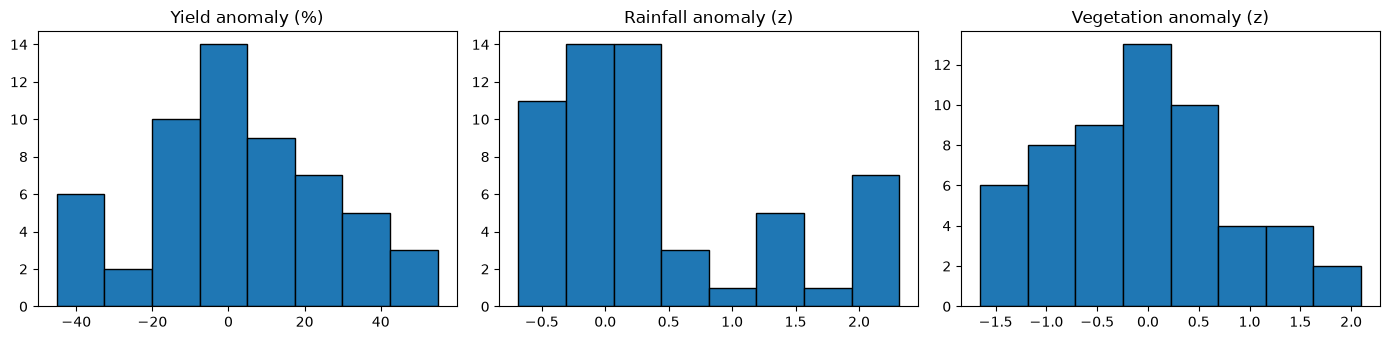

In [15]:
print('Missing values:', int(df.isna().sum().sum()))
print('\nSummary statistics:')
print(df[['yield_kg_ha', 'yield_anom', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col, label in zip(axes, ['yield_anom', 'rain_z', 'ndvi_z'],
                          ['Yield anomaly (%)', 'Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    ax.hist(df[col], bins=8, edgecolor='black')
    ax.set_title(label)
plt.tight_layout(); plt.show()

### Relationships

rain_z vs yield anomaly: Pearson r = 0.06 (p = 0.645), Spearman rho = 0.13 (p = 0.339)
ndvi_z vs yield anomaly: Pearson r = 0.43 (p = 0.001), Spearman rho = 0.41 (p = 0.001)

Correlation between the two inputs: 0.08


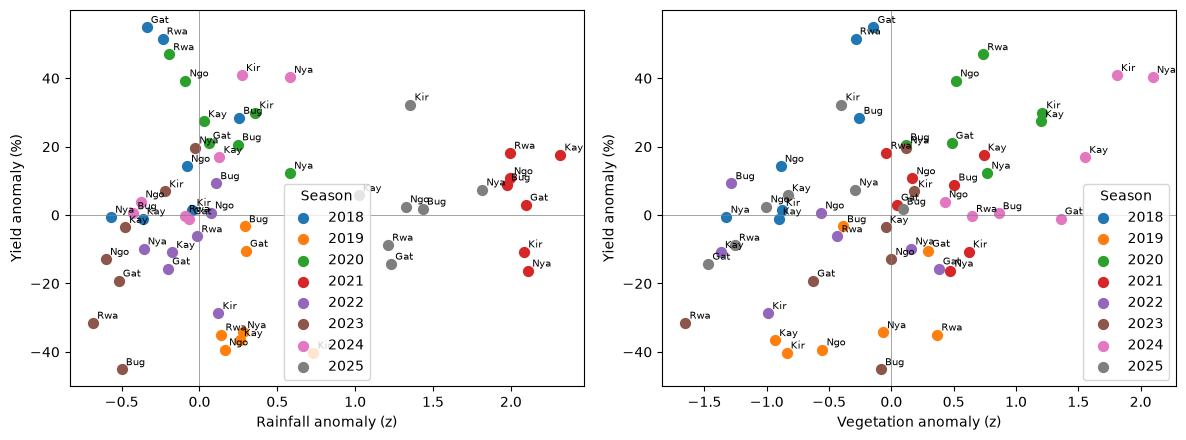

In [16]:
for feat in ['rain_z', 'ndvi_z']:
    r, p_r = stats.pearsonr(df[feat], df['yield_anom'])
    rho, p_s = stats.spearmanr(df[feat], df['yield_anom'])
    print(f'{feat} vs yield anomaly: Pearson r = {r:.2f} (p = {p_r:.3f}), Spearman rho = {rho:.2f} (p = {p_s:.3f})')
r_in, _ = stats.pearsonr(df['rain_z'], df['ndvi_z'])
print(f'\nCorrelation between the two inputs: {r_in:.2f}')

colors = dict(zip(TRAIN_SEASONS, plt.cm.tab10.colors))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat, label in zip(axes, ['rain_z', 'ndvi_z'], ['Rainfall anomaly (z)', 'Vegetation anomaly (z)']):
    for yr, g in df.groupby('season'):
        ax.scatter(g[feat], g['yield_anom'], color=colors[yr], label=str(yr), s=50)
        for _, row in g.iterrows():
            ax.annotate(row['district'][:3], (row[feat], row['yield_anom']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.axhline(0, lw=0.5, color='grey'); ax.axvline(0, lw=0.5, color='grey')
    ax.set_xlabel(label); ax.set_ylabel('Yield anomaly (%)'); ax.legend(title='Season')
plt.tight_layout(); plt.show()

In [17]:
for col in ['yield_anom', 'rain_z', 'ndvi_z']:
    z = (df[col] - df[col].mean()) / df[col].std(ddof=1)
    flagged = df.loc[z.abs() > 2, ['district', 'season', col]]
    print(f'{col}: {len(flagged)} point(s) beyond 2 standard deviations')
    if len(flagged):
        print(flagged.round(2).to_string(index=False))

yield_anom: 3 point(s) beyond 2 standard deviations
 district  season  yield_anom
  Gatsibo    2018       54.94
Rwamagana    2018       51.57
 Bugesera    2023      -45.12
rain_z: 3 point(s) beyond 2 standard deviations
 district  season  rain_z
  Gatsibo    2021    2.10
  Kayonza    2021    2.32
Nyagatare    2021    2.11
ndvi_z: 2 point(s) beyond 2 standard deviations
 district  season  ndvi_z
   Kirehe    2024    1.81
Nyagatare    2024    2.10


### Correlation matrix

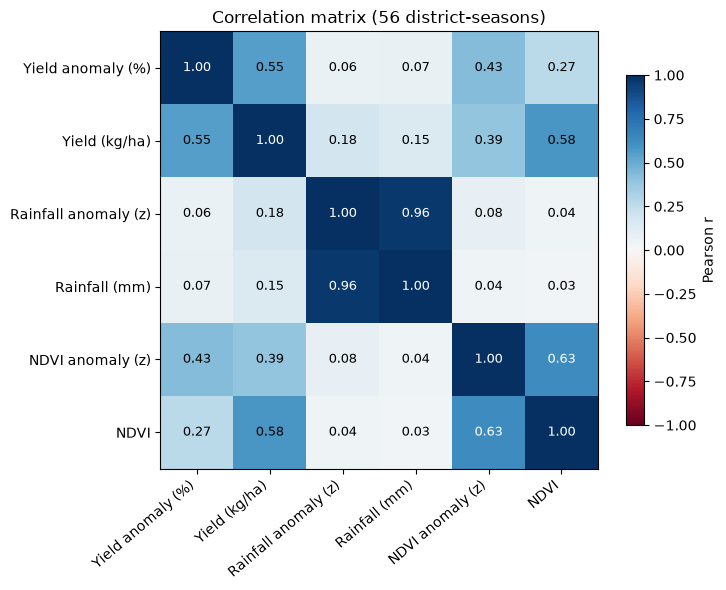

Rainfall anomaly vs yield anomaly: r = 0.06
NDVI anomaly vs yield anomaly:     r = 0.43
Rainfall vs NDVI anomaly:          r = 0.08 (low, so the inputs are not collinear)


In [18]:
# Correlation matrix of the modelling variables (Pearson)
cols = ['yield_anom', 'yield_kg_ha', 'rain_z', 'rain_mm', 'ndvi_z', 'ndvi']
labels = ['Yield anomaly (%)', 'Yield (kg/ha)', 'Rainfall anomaly (z)', 'Rainfall (mm)',
          'NDVI anomaly (z)', 'NDVI']
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap='RdBu', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), labels, rotation=40, ha='right')
ax.set_yticks(range(len(cols)), labels)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                color='white' if abs(v) > 0.6 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson r')
ax.set_title(f'Correlation matrix ({len(df)} district-seasons)')
plt.tight_layout(); plt.show()

print(f"Rainfall anomaly vs yield anomaly: r = {corr.loc['rain_z', 'yield_anom']:.2f}")
print(f"NDVI anomaly vs yield anomaly:     r = {corr.loc['ndvi_z', 'yield_anom']:.2f}")
print(f"Rainfall vs NDVI anomaly:          r = {corr.loc['rain_z', 'ndvi_z']:.2f} (low, so the inputs are not collinear)")

### Yield by district and season

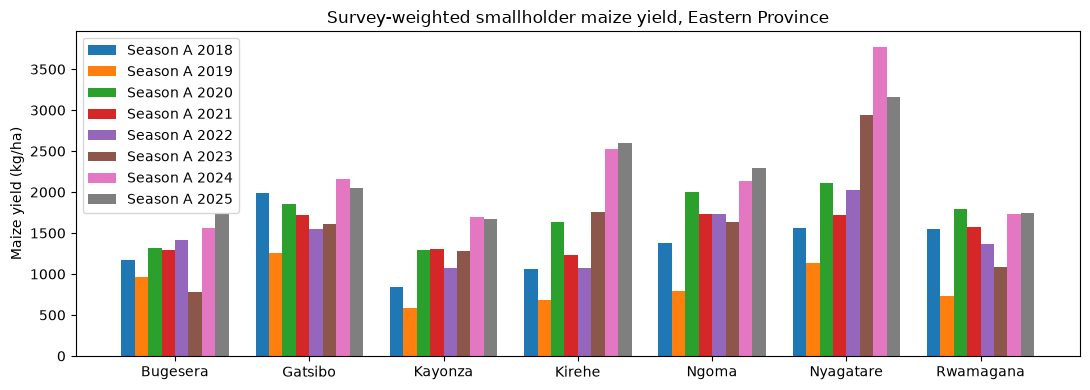

Province-wide mean yield by season (kg/ha):
season
2018    1363.0
2019     877.0
2020    1714.0
2021    1512.0
2022    1462.0
2023    1585.0
2024    2227.0
2025    2177.0


In [19]:
# Maize yield by district and season: the target before it is turned into an anomaly
pivot = df.pivot(index='district', columns='season', values='yield_kg_ha')

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(pivot.columns)
for k, season in enumerate(pivot.columns):
    offset = (k - (len(pivot.columns) - 1) / 2) * width
    ax.bar(np.arange(len(pivot)) + offset, pivot[season], width, label=f'Season A {season}')
ax.set_xticks(range(len(pivot)), pivot.index)
ax.set_ylabel('Maize yield (kg/ha)')
ax.set_title('Survey-weighted smallholder maize yield, Eastern Province')
ax.legend()
plt.tight_layout(); plt.show()

print('Province-wide mean yield by season (kg/ha):')
print(pivot.mean().round(0).to_string())

### Seasonal patterns and cloud cover (EDA check 3)

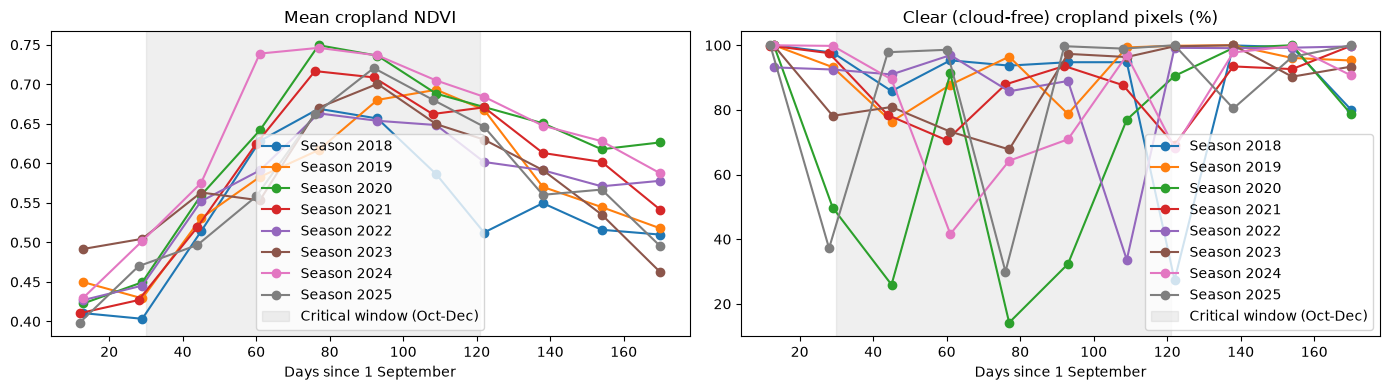

In [20]:
province = districts.union().geometry()

def season_profile(season_year):
    start = ee.Date.fromYMD(season_year - 1, 9, 1)
    end   = ee.Date.fromYMD(season_year, 3, 1)
    def one(img):
        valid = img.select('SummaryQA').lte(1)
        ndvi = img.select('NDVI').multiply(0.0001).updateMask(valid).updateMask(cropland)
        clear = valid.updateMask(cropland)
        stats_ = (ndvi.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)
                  .combine(clear.reduceRegion(ee.Reducer.mean(), province, 250, maxPixels=1e10)))
        return ee.Feature(None, {'date': img.date().format('YYYY-MM-dd'),
                                 'ndvi': stats_.get('NDVI'), 'clear_share': stats_.get('SummaryQA')})
    feats = ee.FeatureCollection(modis.filterDate(start, end).map(one)).getInfo()['features']
    return pd.DataFrame([f['properties'] for f in feats])

profiles = {y: season_profile(y) for y in TRAIN_SEASONS}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for y, p in profiles.items():
    day = (pd.to_datetime(p['date']) - pd.Timestamp(f'{y-1}-09-01')).dt.days
    axes[0].plot(day, p['ndvi'], marker='o', label=f'Season {y}')
    axes[1].plot(day, 100 * p['clear_share'], marker='o', label=f'Season {y}')
for ax, t in zip(axes, ['Mean cropland NDVI', 'Clear (cloud-free) cropland pixels (%)']):
    ax.axvspan(30, 121, alpha=0.12, color='grey', label='Critical window (Oct-Dec)')
    ax.set_title(t); ax.set_xlabel('Days since 1 September'); ax.legend()
plt.tight_layout(); plt.show()

### Sensitivity: peak NDVI
The proposal specifies mean NDVI over the critical window. The seasonal profiles show that 2025 greened later
but peaked higher than 2022 and 2023, which lowers its mean. Peak (maximum) NDVI, as used by Roznik et al. (2022),
is tested alongside mean NDVI. Mean NDVI remains the primary input.

In [21]:
def modis_peak_season(y):
    start, end = window(y)
    def clean(img):
        good = img.select('SummaryQA').lte(1)
        return img.select('NDVI').multiply(0.0001).updateMask(good)
    img = modis.filterDate(start, end).map(clean).max().rename('value')   # highest greenness in the window
    return img.updateMask(cropland).set('season', y)

if os.path.exists(PEAK_CSV):
    peak = pd.read_csv(PEAK_CSV)
    print('Loaded cached peak NDVI:', peak.shape)
else:
    peak = extract(modis_peak_season, MODIS_SEASONS, 250, 'ndvi_peak')
    peak.to_csv(PEAK_CSV, index=False)
    print('Extracted and saved:', peak.shape)

peak['ndvi_peak_z'] = peak.groupby('district')['ndvi_peak'].transform(zscore)
df = df.drop(columns=['ndvi_peak', 'ndvi_peak_z'], errors='ignore').merge(
        peak[['district', 'season', 'ndvi_peak', 'ndvi_peak_z']], on=['district', 'season'], how='left')

r, p = stats.pearsonr(df['ndvi_peak_z'], df['yield_anom'])
print(f'\nPeak NDVI vs yield anomaly: Pearson r = {r:.2f} (p = {p:.3f})')
r_mean, _ = stats.pearsonr(df['ndvi_z'], df['yield_anom'])
print(f'For comparison, mean NDVI: r = {r_mean:.2f}')
print(df.groupby('season')[['ndvi_z', 'ndvi_peak_z']].mean().round(2))

Loaded cached peak NDVI: (175, 3)

Peak NDVI vs yield anomaly: Pearson r = 0.15 (p = 0.285)
For comparison, mean NDVI: r = 0.43
        ndvi_z  ndvi_peak_z
season                     
2018     -0.67        -0.88
2019     -0.30        -0.23
2020      0.72        -0.17
2021      0.36         0.65
2022     -0.59        -0.87
2023     -0.30        -0.15
2024      1.25         1.21
2025     -0.74         0.42


## 8. Model comparison
Models: Ridge, Lasso, quadratic OLS, and a mean-only baseline. Ridge and Lasso tune their penalty with an
inner leave-one-out loop on the training data only (nested cross-validation).
Validation: leave-one-out (as specified in the proposal) and leave-one-season-out (stricter: predicts an unseen year).
Main inputs: rain_z and ndvi_z (mean NDVI). Sensitivity: rain_z and ndvi_peak_z (peak NDVI).

In [22]:
from sklearn.model_selection import LeaveOneGroupOut

def add_squares(X):
    return np.hstack([X, X ** 2])

alphas = np.logspace(-3, 3, 50)
def make_models():
    return {
        'Baseline (mean)': DummyRegressor(strategy='mean'),
        'Ridge': Pipeline([('scale', StandardScaler()),
                           ('model', RidgeCV(alphas=alphas, cv=LeaveOneOut(), scoring='neg_mean_squared_error'))]),
        'Lasso': Pipeline([('scale', StandardScaler()),
                           ('model', LassoCV(alphas=alphas, cv=LeaveOneOut(), max_iter=50000))]),
        'Quadratic OLS': Pipeline([('squares', FunctionTransformer(add_squares)),
                                   ('model', LinearRegression())]),
    }

def evaluate(features):
    X = df[features].to_numpy(); y = df['yield_anom'].to_numpy()
    rows, preds = [], {}
    for scheme, cv in [('Leave-one-out', LeaveOneOut()), ('Leave-one-season-out', LeaveOneGroupOut())]:
        for name, model in make_models().items():
            groups = df['season'] if scheme == 'Leave-one-season-out' else None
            p = cross_val_predict(model, X, y, cv=cv, groups=groups)
            preds[(scheme, name)] = p
            rows.append({'Validation': scheme, 'Model': name,
                         'RMSE': np.sqrt(mean_squared_error(y, p)),
                         'MAE': mean_absolute_error(y, p),
                         'Predictive R2': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)})
    return pd.DataFrame(rows).set_index(['Validation', 'Model']).round(2), preds

results_main, preds_main = evaluate(['rain_z', 'ndvi_z'])
results_peak, preds_peak = evaluate(['rain_z', 'ndvi_peak_z'])

print('MAIN: rainfall + mean NDVI')
print(results_main)
print('\nSENSITIVITY: rainfall + peak NDVI')
print(results_peak)

MAIN: rainfall + mean NDVI
                                       RMSE    MAE  Predictive R2
Validation           Model                                       
Leave-one-out        Baseline (mean)  24.09  18.71          -0.04
                     Ridge            22.26  17.31           0.11
                     Lasso            22.13  17.20           0.13
                     Quadratic OLS    22.69  17.52           0.08
Leave-one-season-out Baseline (mean)  25.58  19.78          -0.17
                     Ridge            24.94  20.00          -0.11
                     Lasso            24.79  19.76          -0.10
                     Quadratic OLS    27.76  22.23          -0.38

SENSITIVITY: rainfall + peak NDVI
                                       RMSE    MAE  Predictive R2
Validation           Model                                       
Leave-one-out        Baseline (mean)  24.09  18.71          -0.04
                     Ridge            24.23  18.77          -0.05
              

### Selected model
Ridge regression on `rain_z` and `ndvi_z`, trained on the 56 district-seasons of 2018–2025.

- **Ridge and Lasso are tied.** Lasso is ahead by 0.01–0.02 in R² under both validation schemes (leave-one-out
  0.13 against 0.11; leave-one-season-out −0.10 against −0.11), a gap well inside the noise of 56 rows. Ridge is
  kept because it was the model specified in the proposal and it keeps both inputs.
- **The index is weak.** It explains about 11% of the variation in unseen district-seasons and none in an unseen
  year (R² below zero means a whole new season is predicted no better than by its average). The earlier version,
  fitted on 2022–2025 only, reported R² 0.51; most of that came from the yield trend over those four seasons
  (detrended, the same 28 rows give about zero).
- **Greenness carries the signal.** October–December crop greenness gets 93% of the weight; October–December
  rainfall adds almost nothing once greenness is known.
- **2019 is the main failure:** harvests fell 34–40% in five districts while rainfall was above normal and
  greenness only slightly low, so the index could not see the loss.
- **Including 2017 makes the index worse** (sensitivity cell below): its imputed yields are 29–93% above the
  trend in a documented drought season.


In [23]:
FEATURES = ['rain_z', 'ndvi_z']
X = df[FEATURES].to_numpy(); y = df['yield_anom'].to_numpy()

best = make_models()['Ridge'].fit(X, y)
ridge = best.named_steps['model']
print(f'Selected penalty strength (alpha): {ridge.alpha_:.3f}')
print('Coefficients (per 1 standard deviation of each input):')
for f, c in zip(FEATURES, ridge.coef_):
    print(f'  {f}: {c:+.2f} percentage points of yield')
print(f'  intercept: {ridge.intercept_:+.2f}')

df['index_loo'] = preds_main[('Leave-one-out', 'Ridge')]
results_main.to_csv(f'{DATA_DIR}/model_results_main.csv')
results_peak.to_csv(f'{DATA_DIR}/model_results_peak.csv')
print('\nResults tables saved to', DATA_DIR.name)

Selected penalty strength (alpha): 6.251
Coefficients (per 1 standard deviation of each input):
  rain_z: +0.66 percentage points of yield
  ndvi_z: +9.17 percentage points of yield
  intercept: +2.86

Results tables saved to data


In [24]:
# Sensitivity: the same pipeline with Season A 2017 (imputed production) added to the training data
d17 = df_all.reset_index(drop=True)
X17, y17 = d17[FEATURES].to_numpy(), d17['yield_anom'].to_numpy()
rows17 = []
for scheme, cv in [('Leave-one-out', LeaveOneOut()), ('Leave-one-season-out', LeaveOneGroupOut())]:
    groups = d17['season'] if scheme == 'Leave-one-season-out' else None
    p = cross_val_predict(make_models()['Ridge'], X17, y17, cv=cv, groups=groups)
    rows17.append({'Validation': scheme, 'R2 with 2017': 1 - np.sum((y17 - p) ** 2) / np.sum((y17 - y17.mean()) ** 2),
                   'R2 without (main)': results_main.loc[(scheme, 'Ridge'), 'Predictive R2']})
print(pd.DataFrame(rows17).round(2).to_string(index=False))
print('\nSeason A 2017 (documented drought): yield anomaly against the satellite inputs')
print(d17[d17['season'] == 2017][['district', 'yield_anom', 'rain_z', 'ndvi_z']].round(2).to_string(index=False))


          Validation  R2 with 2017  R2 without (main)
       Leave-one-out         -0.07               0.11
Leave-one-season-out         -0.40              -0.11

Season A 2017 (documented drought): yield anomaly against the satellite inputs
 district  yield_anom  rain_z  ndvi_z
 Bugesera       76.27   -0.76    0.40
  Gatsibo       49.40    0.21   -1.16
  Kayonza       93.27   -0.07   -0.50
   Kirehe       55.32   -1.02   -1.94
    Ngoma       48.02   -0.77   -2.66
Nyagatare       29.06    0.23   -0.55
Rwamagana       63.59   -0.16   -0.83


### Sensitivity: a longer satellite window
The index misses Season A 2019: harvests fell 34–40% in five districts while October–December rainfall
was above normal. If the loss came from a dry spell after December, a window reaching into January or
February should see it. Four windows are compared with the same Ridge model, target and validation; the
list is kept short so the comparison does not go looking for a lucky window. Leave-one-season-out decides,
because an insurer always prices a season the model has not seen.

A longer window has a cost: the index can only be published once the window closes, so an October–February
window means paying in March, after the harvest, instead of in January.


In [25]:
WINDOWS = {'Oct-Dec (main)': (10, 3), 'Oct-Jan': (10, 4), 'Oct-Feb': (10, 5), 'Nov-Feb': (11, 4)}
WIN_CSV = DATA_DIR / 'satellite_windows.csv'

def window_fns(start_month, n_months):
    """Rainfall total and mean NDVI over n_months from start_month of the year before season Y."""
    def span(y):
        start = ee.Date.fromYMD(ee.Number(y).subtract(1), start_month, 1)
        return start, start.advance(n_months, 'month')
    def rain(y):
        s, e = span(y)
        return chirps.filterDate(s, e).sum().rename('value').updateMask(cropland).set('season', y)
    def ndvi(y):
        s, e = span(y)
        def clean(img):
            return img.select('NDVI').multiply(0.0001).updateMask(img.select('SummaryQA').lte(1))
        return modis.filterDate(s, e).map(clean).mean().rename('value').updateMask(cropland).set('season', y)
    return rain, ndvi

if os.path.exists(WIN_CSV):
    win = pd.read_csv(WIN_CSV)
    print('Loaded cached window extracts:', win.shape)
else:
    parts = []
    for name, (m0, n) in WINDOWS.items():
        rain_fn, ndvi_fn = window_fns(m0, n)
        r = extract(rain_fn, CHIRPS_SEASONS, 1000, 'rain_mm')
        v = extract(ndvi_fn, MODIS_SEASONS, 250, 'ndvi')
        parts.append(r.merge(v, on=['district', 'season'], how='left').assign(window=name))
        print(f'{name}: extracted {len(r)} district-seasons')
    win = pd.concat(parts, ignore_index=True)
    win.to_csv(WIN_CSV, index=False)

# The main window must reproduce the satellite table used everywhere else.
check = win[win['window'] == 'Oct-Dec (main)'].merge(sat, on=['district', 'season'], suffixes=('', '_main'))
assert np.allclose(check['rain_mm'], check['rain_mm_main']), 'Oct-Dec rainfall does not match Section 4'
assert np.allclose(check['ndvi'].dropna(), check['ndvi_main'].dropna()), 'Oct-Dec NDVI does not match Section 4'
print('Check passed: the Oct-Dec extract reproduces the main satellite data')


Oct-Dec (main): extracted 308 district-seasons


Oct-Jan: extracted 308 district-seasons


Oct-Feb: extracted 308 district-seasons


Nov-Feb: extracted 308 district-seasons
Check passed: the Oct-Dec extract reproduces the main satellite data


In [26]:
target = df[['district', 'season', 'yield_anom']]
rows, seen_2019 = [], {}
for name in WINDOWS:
    w = win[win['window'] == name].copy()
    w['rain_z'] = w.groupby('district')['rain_mm'].transform(zscore)
    w['ndvi_z'] = w.groupby('district')['ndvi'].transform(zscore)
    d = target.merge(w[['district', 'season', 'rain_z', 'ndvi_z']], on=['district', 'season'])
    Xw, yw = d[FEATURES].to_numpy(), d['yield_anom'].to_numpy()
    out = {'Window': name}
    for scheme, cv in [('Leave-one-out', LeaveOneOut()), ('Leave-one-season-out', LeaveOneGroupOut())]:
        groups = d['season'] if scheme == 'Leave-one-season-out' else None
        p = cross_val_predict(make_models()['Ridge'], Xw, yw, cv=cv, groups=groups)
        out[f'R2 {scheme}'] = 1 - np.sum((yw - p) ** 2) / np.sum((yw - yw.mean()) ** 2)
        if scheme == 'Leave-one-out':
            loo = p
    low_w = yw <= LOW_YIELD_THRESHOLD
    scan_w = [(t, (loo <= t)[low_w].mean(), (loo <= t)[~low_w].mean()) for t in range(-1, -31, -1)]
    t, hit, fp = max(scan_w, key=lambda s: s[1] - s[2])
    out.update({'r rain': stats.pearsonr(d['rain_z'], yw)[0], 'r NDVI': stats.pearsonr(d['ndvi_z'], yw)[0],
                'Trigger': t, 'Hit rate': hit, 'False payout rate': fp})
    rows.append(out)
    is19 = d['season'] == 2019
    seen_2019[name] = pd.Series(loo[is19], index=d.loc[is19, 'district'])

window_results = pd.DataFrame(rows).set_index('Window')
print(window_results.round(2).to_string())

print('\nSeason A 2019: actual yield change and the leave-one-out index from each window (%)')
actual_2019 = target[target['season'] == 2019].set_index('district')['yield_anom']
print(pd.concat({'Actual': actual_2019, **seen_2019}, axis=1).round(1).to_string())


                R2 Leave-one-out  R2 Leave-one-season-out  r rain  r NDVI  Trigger  Hit rate  False payout rate
Window                                                                                                         
Oct-Dec (main)              0.11                    -0.11    0.06    0.43       -2      0.50               0.22
Oct-Jan                     0.08                    -0.16    0.02    0.39       -9      0.12               0.02
Oct-Feb                     0.10                    -0.16    0.09    0.42       -4      0.31               0.12
Nov-Feb                     0.10                    -0.58   -0.07    0.41       -1      0.56               0.28

Season A 2019: actual yield change and the leave-one-out index from each window (%)
           Actual  Oct-Dec (main)  Oct-Jan  Oct-Feb  Nov-Feb
district                                                    
Bugesera     -3.3            -1.0     -0.1     -1.7     -4.5
Gatsibo     -10.5             6.7      7.8      7.3      4.9

**Result: October–December stays.** No longer window does better, and the strict leave-one-season-out
score gets worse with every alternative (−0.16 to −0.58 against −0.11). None of them sees the 2019 loss
either: with January and February included, rainfall and crop greenness still looked normal in the five
districts that lost 34–40% of their harvest. The 2019 failure is therefore not a timing problem in the
index. Something the satellites do not measure caused it (a pest outbreak such as fall armyworm, a market or
input shock, or an error in that year's survey), which is the kind of loss a weather index cannot insure
and a field-check rule would have to cover.


### Model architecture

The selected model is a regularised linear regression, chosen because so few observations cannot support
a model with many free parameters (proposal §3.9). It has no hidden layers or activation functions.

```
rain_z ─┐
        ├─► StandardScaler ─► Ridge regression ─► predicted yield change ─► payout rule
ndvi_z ─┘   (mean 0, sd 1)    (linear, L2 penalty)  (the drought index, %)    (0 above the trigger,
                                                                              rising to 100% at the exit)
```

| Component | Choice |
|---|---|
| Inputs | 2 features: rainfall anomaly `rain_z`, vegetation anomaly `ndvi_z` |
| Preprocessing | `StandardScaler`, so the penalty treats both inputs equally |
| Model | `index = b0 + b1·rain + b2·ndvi` (standardised inputs) |
| Loss | squared error + α·(b1² + b2²) (Ridge / L2 penalty) |
| Optimisation | closed-form least-squares solution (no gradient descent or epochs needed) |
| Hyperparameter | α chosen from 50 values between 0.001 and 1000 by leave-one-out cross-validation on the training rows only (nested inside the outer validation) |
| Output | predicted yield anomaly (%), which is the drought index |
| Decision layer | trigger and exit, chosen in Section 9 |

The cell below shows the fitted pipeline, the learned weights, and how the validation error changes
with α.

Pipeline: scale (StandardScaler) -> model (RidgeCV)
Scaler mean: [ 0.398 -0.034], scale: [0.838 0.843]
index = 2.86 +0.66 x rain (standardised) +9.17 x ndvi (standardised)
Selected alpha: 6.251


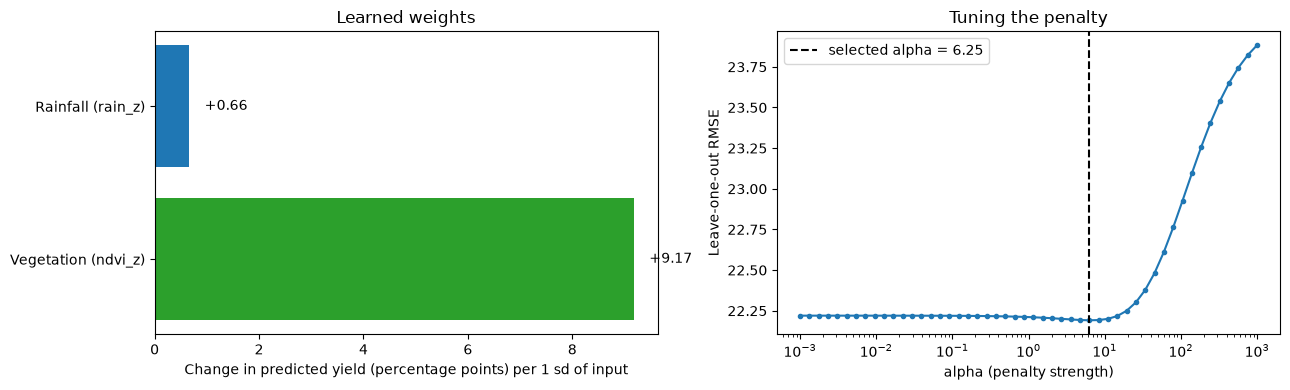

Rainfall carries 7% of the model weight, vegetation 93%.


In [27]:
print('Pipeline:', ' -> '.join(f'{name} ({type(step).__name__})' for name, step in best.steps))
print(f'Scaler mean: {best.named_steps["scale"].mean_.round(3)}, scale: {best.named_steps["scale"].scale_.round(3)}')
b0, (b1, b2) = round(ridge.intercept_, 2) + 0.0, ridge.coef_
print(f'index = {b0:.2f} {b1:+.2f} x rain (standardised) {b2:+.2f} x ndvi (standardised)')
print(f'Selected alpha: {ridge.alpha_:.3f}')

# Validation error for each alpha (leave-one-out, same folds as the tuning)
from sklearn.linear_model import Ridge
curve = []
for a in alphas:
    p = cross_val_predict(Pipeline([('scale', StandardScaler()), ('model', Ridge(alpha=a))]),
                          X, y, cv=LeaveOneOut())
    curve.append(np.sqrt(mean_squared_error(y, p)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(['Vegetation (ndvi_z)', 'Rainfall (rain_z)'], [b2, b1], color=['tab:green', 'tab:blue'])
for v, ypos in zip([b2, b1], [0, 1]):
    axes[0].text(v + 0.3, ypos, f'{v:+.2f}', va='center')
axes[0].set_xlabel('Change in predicted yield (percentage points) per 1 sd of input')
axes[0].set_title('Learned weights')

axes[1].semilogx(alphas, curve, marker='.')
axes[1].axvline(ridge.alpha_, ls='--', color='black', label=f'selected alpha = {ridge.alpha_:.2f}')
axes[1].set_xlabel('alpha (penalty strength)'); axes[1].set_ylabel('Leave-one-out RMSE')
axes[1].set_title('Tuning the penalty'); axes[1].legend()
plt.tight_layout(); plt.show()

share = abs(b1) / (abs(b1) + abs(b2))
print(f'Rainfall carries {share:.0%} of the model weight, vegetation {1 - share:.0%}.')

## 9. Payout trigger, exit, and basis risk
Index = the selected model's predicted yield anomaly (leave-one-out predictions, so thresholds are not fitted to the same data).
Payouts start at the trigger and rise linearly to the exit. A low-yield season is one at least 10% below the district average.

In [28]:
index = df['index_loo'].to_numpy()
low = df['yield_anom'].to_numpy() <= LOW_YIELD_THRESHOLD
print(f'Low-yield district-seasons: {low.sum()} of {len(df)}\n')

scan = []
for t in np.arange(-1, -31, -1):
    pays = index <= t
    scan.append({'trigger': t,
                 'hit_rate': pays[low].mean(),
                 'false_payout_rate': pays[~low].mean()})
scan = pd.DataFrame(scan)
scan['score'] = scan['hit_rate'] - scan['false_payout_rate']
TRIGGER = float(scan.loc[scan['score'].idxmax(), 'trigger'])
EXIT = TRIGGER - 20.0
best_row = scan.loc[scan['trigger'] == TRIGGER].iloc[0]
print(f'Trigger: {TRIGGER:.0f}% | Exit: {EXIT:.0f}%')
print(f'Hit rate: {best_row.hit_rate:.0%} | False payout rate: {best_row.false_payout_rate:.0%}')

def payout_fraction(v):
    return np.clip((TRIGGER - v) / (TRIGGER - EXIT), 0, 1)

df['payout'] = payout_fraction(df['index_loo'])
df['payout_if_actual'] = payout_fraction(df['yield_anom'])
df['basis_risk'] = (df['payout'] - df['payout_if_actual']).abs()

print('\nBasis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):')
print(df.groupby('district')['basis_risk'].mean().round(2).sort_values(ascending=False).to_string())

print('\nSeason by season:')
print(df[['district', 'season', 'yield_anom', 'index_loo', 'payout', 'payout_if_actual']].round(2).to_string(index=False))

Low-yield district-seasons: 16 of 56

Trigger: -2% | Exit: -22%
Hit rate: 50% | False payout rate: 22%

Basis risk per district (0 = index pays exactly what the loss justifies, 1 = completely wrong):
district
Nyagatare    0.33
Kirehe       0.29
Ngoma        0.27
Gatsibo      0.25
Rwamagana    0.21
Bugesera     0.20
Kayonza      0.18

Season by season:
 district  season  yield_anom  index_loo  payout  payout_if_actual
 Bugesera    2018       28.37      -0.22    0.00              0.00
  Gatsibo    2018       54.94      -0.66    0.00              0.00
  Kayonza    2018       -1.05      -7.52    0.28              0.00
   Kirehe    2018        1.47      -7.02    0.25              0.00
    Ngoma    2018       14.34      -7.91    0.30              0.00
Nyagatare    2018       -0.55     -12.86    0.54              0.00
Rwamagana    2018       51.57      -1.97    0.00              0.00
 Bugesera    2019       -3.33      -1.04    0.00              0.07
  Gatsibo    2019      -10.49       6.69   

### Trigger selection
Every whole-number trigger from -1% to -30% is scored by hit rate minus false payout rate on the
leave-one-out index, and the best-scoring trigger is kept (the first, if several tie). The chart and
the table below show the trade-off: an earlier trigger pays in more poor seasons but makes more false payouts.

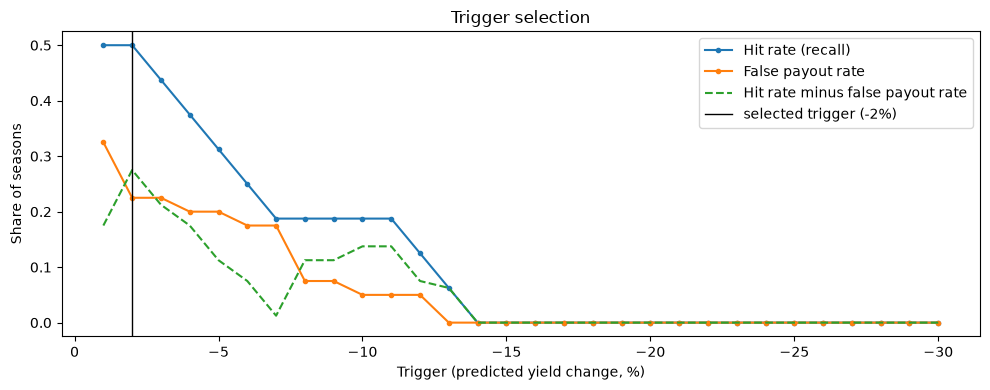

Best-scoring trigger(s):
 trigger hit_rate false_payout_rate  score
      -2      50%               22%   0.28


In [29]:
# How the trigger was chosen: hit rate against false payout rate for every candidate trigger
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(scan['trigger'], scan['hit_rate'], marker='.', label='Hit rate (recall)')
ax.plot(scan['trigger'], scan['false_payout_rate'], marker='.', label='False payout rate')
ax.plot(scan['trigger'], scan['score'], ls='--', label='Hit rate minus false payout rate')
ax.axvline(TRIGGER, color='black', lw=1, label=f'selected trigger ({TRIGGER:.0f}%)')
ax.set_xlabel('Trigger (predicted yield change, %)'); ax.set_ylabel('Share of seasons')
ax.invert_xaxis(); ax.legend(); ax.set_title('Trigger selection')
plt.tight_layout(); plt.show()

top = scan[scan['score'] == scan['score'].max()]
print('Best-scoring trigger(s):')
print(top.assign(hit_rate=top['hit_rate'].map('{:.0%}'.format),
                 false_payout_rate=top['false_payout_rate'].map('{:.0%}'.format),
                 score=top['score'].round(2)).to_string(index=False))

### Initial performance metrics of the selected model

Two views of performance, both on leave-one-out predictions (each district-season predicted by a model
that never saw it):

1. **Regression:** how close the predicted yield change is to the actual one (RMSE, MAE, predictive R²,
   reported in Section 8).
2. **Classification:** the insurance decision. A season is a true *poor season* when the actual yield is
   at least 10% below the district average; the index *pays* when its prediction is at or below the
   trigger. This gives accuracy, precision, recall (the hit rate) and F1.

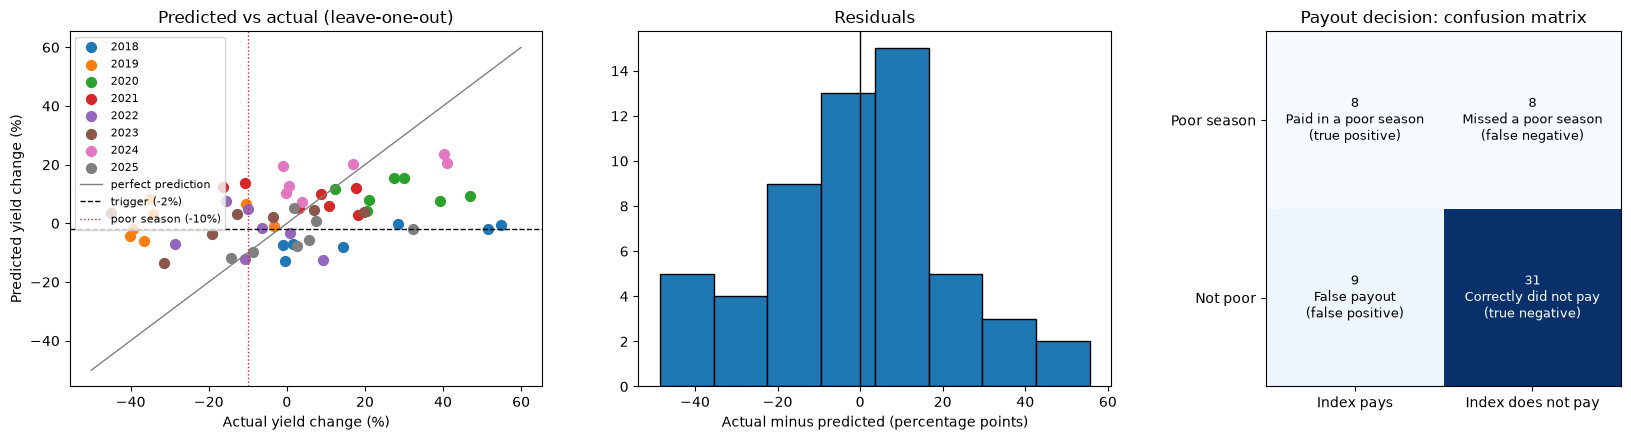

           Metric Value                                                           Meaning
         Accuracy   70% share of the 56 seasons where the pay / no-pay decision was right
        Precision   47%        of the seasons the index paid, share that were really poor
Recall (hit rate)   50%                         of the poor seasons, share the index paid
         F1-score   48%                                   balance of precision and recall
      Specificity   78%      of the normal seasons, share the index correctly did not pay
False payout rate   22%     of the normal seasons, share the index paid (1 - specificity)

Regression (leave-one-out): RMSE 22.26, MAE 17.31, predictive R2 0.11


In [30]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)

# 1. Regression view
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ax = axes[0]
for yr, g in df.groupby('season'):
    ax.scatter(g['yield_anom'], g['index_loo'], s=50, label=str(yr))
lim = [df[['yield_anom', 'index_loo']].min().min() - 5, df[['yield_anom', 'index_loo']].max().max() + 5]
ax.plot(lim, lim, color='grey', lw=1, label='perfect prediction')
ax.axhline(TRIGGER, ls='--', color='black', lw=1, label=f'trigger ({TRIGGER:.0f}%)')
ax.axvline(LOW_YIELD_THRESHOLD, ls=':', color='tab:red', lw=1, label='poor season (-10%)')
ax.set_xlabel('Actual yield change (%)'); ax.set_ylabel('Predicted yield change (%)')
ax.set_title('Predicted vs actual (leave-one-out)'); ax.legend(fontsize=8)

resid = df['yield_anom'] - df['index_loo']
axes[1].hist(resid, bins=8, edgecolor='black')
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('Actual minus predicted (percentage points)'); axes[1].set_title('Residuals')

# 2. Classification view: the payout decision
actual_poor = df['yield_anom'] <= LOW_YIELD_THRESHOLD
index_pays = df['index_loo'] <= TRIGGER
cm = confusion_matrix(actual_poor, index_pays, labels=[True, False])
ax = axes[2]
ax.imshow(cm, cmap='Blues')
names = [['Paid in a poor season\n(true positive)', 'Missed a poor season\n(false negative)'],
         ['False payout\n(false positive)', 'Correctly did not pay\n(true negative)']]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]}\n{names[i][j]}', ha='center', va='center', fontsize=9,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xticks([0, 1], ['Index pays', 'Index does not pay'])
ax.set_yticks([0, 1], ['Poor season', 'Not poor'])
ax.set_title('Payout decision: confusion matrix')
plt.tight_layout(); plt.show()

tn = cm[1, 1]; fp = cm[1, 0]
metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall (hit rate)', 'F1-score',
               'Specificity', 'False payout rate'],
    'Value': [accuracy_score(actual_poor, index_pays), precision_score(actual_poor, index_pays),
              recall_score(actual_poor, index_pays), f1_score(actual_poor, index_pays),
              tn / (tn + fp), fp / (tn + fp)],
    'Meaning': [f'share of the {len(df)} seasons where the pay / no-pay decision was right',
                'of the seasons the index paid, share that were really poor',
                'of the poor seasons, share the index paid',
                'balance of precision and recall',
                'of the normal seasons, share the index correctly did not pay',
                'of the normal seasons, share the index paid (1 - specificity)'],
})
metrics['Value'] = metrics['Value'].map('{:.0%}'.format)
print(metrics.to_string(index=False))

reg = results_main.loc[('Leave-one-out', 'Ridge')]
print(f"\nRegression (leave-one-out): RMSE {reg['RMSE']:.2f}, MAE {reg['MAE']:.2f}, "
      f"predictive R2 {reg['Predictive R2']:.2f}")

## 10. Check against documented drought years
The selected model is applied to satellite data for every season since 2001 (not used in training).
Niyonsenga et al. (2024) identify 2003-2006 and 2013-2017 as Rwanda's most severe drought years.
Seasons are compared by the calendar year of their critical window (Season Y's window falls in Y-1).

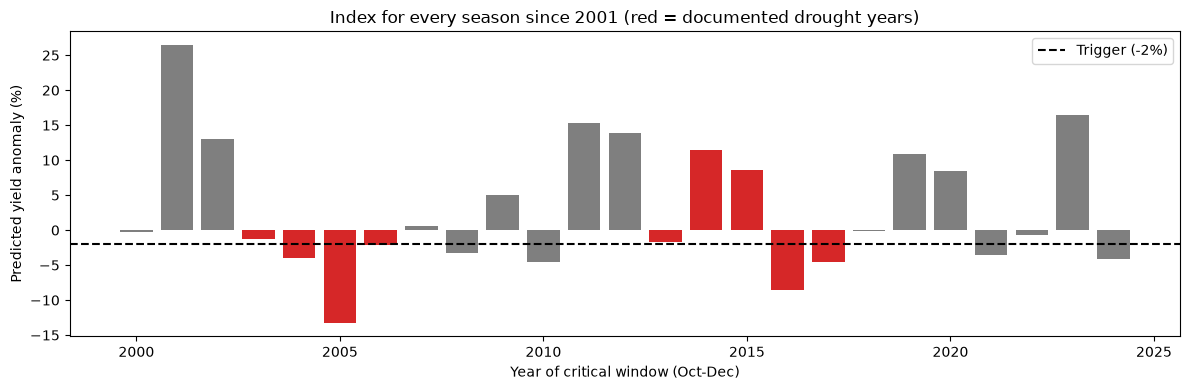

Documented drought years: payout in 54% of district-seasons (34 of 63)
Other years: payout in 23% of district-seasons (26 of 112)

By year:
             index  districts_paid  drought
window_year                                
2000          -0.2               2    False
2001          26.4               0    False
2002          13.0               0    False
2003          -1.3               4     True
2004          -4.0               4     True
2005         -13.2               7     True
2006          -2.2               5     True
2007           0.5               2    False
2008          -3.3               5    False
2009           5.0               0    False
2010          -4.6               4    False
2011          15.4               0    False
2012          13.9               0    False
2013          -1.7               4     True
2014          11.4               0     True
2015           8.6               0     True
2016          -8.6               6     True
2017          -4.5      

In [31]:
hist = sat.dropna(subset=FEATURES).copy()
hist['index'] = best.predict(hist[FEATURES].to_numpy())
hist['window_year'] = hist['season'] - 1
hist['pays'] = hist['index'] <= TRIGGER
hist['drought_year'] = hist['window_year'].isin(DROUGHT_YEARS)

by_year = hist.groupby('window_year').agg(index=('index', 'mean'), districts_paid=('pays', 'sum'))

plt.figure(figsize=(12, 4))
plt.bar(by_year.index, by_year['index'],
        color=['tab:red' if y in DROUGHT_YEARS else 'tab:grey' for y in by_year.index])
plt.axhline(TRIGGER, ls='--', color='black', label=f'Trigger ({TRIGGER:.0f}%)')
plt.xlabel('Year of critical window (Oct-Dec)'); plt.ylabel('Predicted yield anomaly (%)')
plt.title('Index for every season since 2001 (red = documented drought years)')
plt.legend(); plt.tight_layout(); plt.show()

for label, g in [('Documented drought years', hist[hist['drought_year']]),
                 ('Other years', hist[~hist['drought_year']])]:
    print(f'{label}: payout in {g["pays"].mean():.0%} of district-seasons ({g["pays"].sum()} of {len(g)})')

print('\nBy year:')
print(by_year.assign(drought=by_year.index.isin(DROUGHT_YEARS)).round(1).to_string())

## 11. Export for the backend
Saves the model (coefficients, scaler, thresholds), the calibration district-seasons, and the index for every
district-season since 1982, straight into `backend/data/`. A final check confirms the exported numbers reproduce the fitted model.

In [32]:
os.makedirs(EXPORT_DIR, exist_ok=True)

scaler = best.named_steps['scale']

# 1. Model and summary numbers
model_export = {
    'model': 'Ridge',
    'features': FEATURES,
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(),
    'coefficients': ridge.coef_.tolist(),
    'intercept': float(ridge.intercept_),
    'alpha': float(ridge.alpha_),
    'trigger': TRIGGER,
    'exit': EXIT,
    'low_yield_threshold': LOW_YIELD_THRESHOLD,
    'hit_rate': float(best_row.hit_rate),
    'false_payout_rate': float(best_row.false_payout_rate),
    'window_months': [WIN_START_MONTH, WIN_END_MONTH],
    'drought_years': DROUGHT_YEARS,
    'validation_main': results_main.reset_index().to_dict(orient='records'),
    'validation_peak_ndvi': results_peak.reset_index().to_dict(orient='records'),
}
with open(f'{EXPORT_DIR}/model.json', 'w') as f:
    json.dump(model_export, f, indent=2)

# 2. The calibration district-seasons
calib = df[['district', 'season', 'yield_kg_ha', 'yield_anom', 'rain_z', 'ndvi_z',
            'index_loo', 'payout', 'payout_if_actual', 'basis_risk']].round(4)
calib.to_csv(f'{EXPORT_DIR}/calibration.csv', index=False)

# 3. Every district-season since 1982
seasons_out = sat[['district', 'season', 'rain_mm', 'ndvi', 'rain_z', 'ndvi_z']].copy()
has_both = seasons_out['ndvi_z'].notna()
seasons_out.loc[has_both, 'index'] = best.predict(seasons_out.loc[has_both, FEATURES].to_numpy())
seasons_out['payout'] = payout_fraction(seasons_out['index'])
seasons_out['window_year'] = seasons_out['season'] - 1
seasons_out['drought_year'] = seasons_out['window_year'].isin(DROUGHT_YEARS)
seasons_out.round(4).to_csv(f'{EXPORT_DIR}/seasons.csv', index=False)

# Check: the saved numbers alone reproduce the model's predictions
m = model_export
Xs = (df[FEATURES].to_numpy() - np.array(m['scaler_mean'])) / np.array(m['scaler_scale'])
manual = Xs @ np.array(m['coefficients']) + m['intercept']
assert np.allclose(manual, best.predict(df[FEATURES].to_numpy())), 'Export does not reproduce the model'

print('Export check passed: saved coefficients reproduce the model exactly\n')
for fn in ['model.json', 'calibration.csv', 'seasons.csv']:
    print(f'{fn}: {os.path.getsize(f"{EXPORT_DIR}/{fn}") / 1024:.1f} KB')
print(f'\nseasons.csv: {len(seasons_out)} rows, {seasons_out["index"].notna().sum()} with an index (2001 onward)')

Export check passed: saved coefficients reproduce the model exactly

model.json: 3.0 KB
calibration.csv: 3.8 KB
seasons.csv: 17.3 KB

seasons.csv: 308 rows, 175 with an index (2001 onward)


## 12. Deployment option: web dashboard and API

The exported model (Section 11) is served by a working MVP in the project repository
(https://github.com/JokMaker/parametric-drought-simulator):

- **API (FastAPI):** loads `model.json`, `calibration.csv` and `seasons.csv`, applies the saved scaler
  and coefficients, and serves `/api/model`, `/api/simulate`, `/api/history`, `/api/basis-risk` and
  `/api/seasons`. Interactive **Swagger UI** at `http://localhost:8000/docs`.
- **Dashboard (Next.js):** Overview, District Explorer (payout and the reason for it), Drought History
  and Basis Risk.
- **Run:** `docker compose up --build` from the repository root, then open `http://localhost:3000`.
- **Checks:** backend tests confirm the API reproduces this notebook's results (index formula on all
  175 district-seasons, hit and false payout rates, drought-year totals, basis risk).

**Swagger UI**

![API documentation](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/api-docs.png)

**District Explorer: Rwamagana, Season A 2023**

![District Explorer](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/explorer-rwamagana-2023.png)

**Drought History**

![Drought History](https://raw.githubusercontent.com/JokMaker/parametric-drought-simulator/main/docs/screenshots/drought-history.png)